SOCIAL MEDIA ENGAGEMENT ANALYTICS USING PYTHON

Task 1 : Data import & setup

imported dataset using pandas

In [2]:
import pandas as pd

In [3]:
from google.colab import files
uploaded=files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


In [4]:
df=pd.read_csv('social_media_engagement_5000.csv')
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


df.info() shows each columns its datatype and non null count

convert date columns to datetime

the column posted at is a date column but the datatype is in object it converted into datetime using pd.to_datetime

In [7]:
df['posted_at']=pd.to_datetime(df['posted_at'],errors='coerce')

In [11]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


Task 2 : DATA CLEANING

In [12]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


df.isnull().sum() used to find the missing values in each column

In [13]:
df['age']=df['age'].fillna(df['age'].median())

In [14]:
df['gender']=df['gender'].fillna('Unknown')

In [15]:
df['likes']=df['likes'].fillna(df['likes'].median())
df['comments']=df['comments'].fillna(df['comments'].median())
df['shares']=df['shares'].fillna(df['shares'].median())

In [16]:
df['sentiment']=df['sentiment'].fillna(df['sentiment'].mode()[0])

missing values are imputed with median and mode.

missing values in gender column is filled with unknown.

missing values in age, like, share and comments filled using median and missing values in sentiments filled using mode

In [17]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


Duplicate handling

df.duplicated().sum() gives number of duplicate rows

df[df.duplicated()] shows the duplicated rows

in the data set there is no duplicates

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df[df.duplicated()]

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate


DATA FORMATTING

using .unique() checked unique values in each column to verify the accuracy of data

In [20]:
df['gender'].unique()

array(['Female', 'Male', 'Other', 'Unknown'], dtype=object)

In [21]:
df['post_type'].unique()

array(['image', 'reel', 'text', 'video'], dtype=object)

In [22]:
df['post_category'].unique()

array(['fitness', 'food', 'tech', 'travel', 'fashion', 'lifestyle',
       'education', 'music'], dtype=object)

In [23]:
df['sentiment'].unique()

array(['negative', 'positive', 'neutral'], dtype=object)

In [24]:
df['is_verified'].unique()

array([False,  True])

In [25]:
df['device_type'].unique()

array(['mobile', 'tablet', 'desktop'], dtype=object)

Feature cleaning

extract hashtag counts

df['hashtags'].str.count('#') counts the matching pattern in each hashtag

In [128]:
df['hashtags'].str.count('#').head(10)

,hashtags
0,3
1,1
2,1
3,3
4,1
5,1
6,1
7,3
8,3
9,2


TASK 3 : DATA EXPLORATION USING PANDAS

View dataset structure using head(), tail(),shape and columns


*   df.head() shows first five rows
*   df.tail() shows last five rows

*   df.shape gives the number of rows and columns
*   df.columns gives the name of each columns in the dataset





In [26]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372


In [27]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


In [29]:
df.shape

(5000, 19)

In [28]:

df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

check datatype and info with info() and dtypes




*   df.info() gives the column names datatype and non null values of each column. since we imputed the misiing values there is no null values in any column
*   df.dtypes gives the datatype of each columns




In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [31]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


generate summary statistics using describe()

df.describe() gives the count, mean, standard deviation, minimum, maximum and quartiles for numeric columns.

df.describe(include=object) gives the statistical analysis for categorical columns

In [32]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029


In [33]:
df.describe(include=object)

,gender,country,post_type,post_category,device_type,sentiment,hashtags
count,5000,5000,5000,5000,5000,5000,5000
unique,4,10,4,8,3,3,761
top,Male,India,reel,fitness,mobile,positive,#tech
freq,1699,535,1283,675,1684,2513,201


analyze categorical distribution using value counts(), unique(), and nunique()


*   df['post_type'].value_counts() find the number for each post type
*   df['post_type'].unique() find the unique post types

*   df['post_type'].nunique() counts distinct post type
we apply the same for each categorical columns





In [34]:
df['post_type'].value_counts()

,count
post_type,
reel,1283
image,1247
text,1245
video,1225


In [35]:
df['post_type'].unique()

array(['image', 'reel', 'text', 'video'], dtype=object)

In [36]:
df['post_type'].nunique()

4

In [38]:
df['gender'].value_counts()


,count
gender,
Male,1699
Other,1581
Female,1570
Unknown,150


In [39]:
df['gender'].unique()


array(['Female', 'Male', 'Other', 'Unknown'], dtype=object)

In [40]:

df['gender'].nunique()

4

In [41]:
df['country'].value_counts()

,count
country,
India,535
Canada,513
Brazil,504
UAE,503
USA,501
France,496
UK,493
Australia,493
Germany,490


In [42]:
df['country'].unique()

array(['Brazil', 'UK', 'France', 'Canada', 'Japan', 'Australia', 'India',
       'UAE', 'Germany', 'USA'], dtype=object)

In [43]:
df['country'].nunique()

10

In [44]:
df['post_type'].value_counts()

,count
post_type,
reel,1283
image,1247
text,1245
video,1225


In [45]:
df['post_type'].unique()

array(['image', 'reel', 'text', 'video'], dtype=object)

In [46]:
df['post_type'].nunique()

4

In [48]:
df['device_type'].value_counts()

,count
device_type,
mobile,1684
tablet,1658
desktop,1658


In [49]:
df['device_type'].unique()

array(['mobile', 'tablet', 'desktop'], dtype=object)

In [50]:
df['device_type'].nunique()

3

create a correlation matrix for numeric fields

In [51]:
numeric_df=df.select_dtypes(include='number')
correlation_matrix=numeric_df.corr()
print(correlation_matrix)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006688  0.020051  0.025811 -0.033395  0.013763   
age              -0.006688  1.000000 -0.013153 -0.036322 -0.007284  0.013871   
post_id           0.020051 -0.013153  1.000000  0.014526 -0.010540  0.001846   
likes             0.025811 -0.036322  0.014526  1.000000 -0.018421  0.004712   
comments         -0.033395 -0.007284 -0.010540 -0.018421  1.000000  0.006142   
shares            0.013763  0.013871  0.001846  0.004712  0.006142  1.000000   
watch_time_sec   -0.016847  0.005542  0.018374  0.008710 -0.016351  0.014658   
impression_count  0.015326  0.013322 -0.007709  0.007952 -0.009395 -0.005204   
follower_count    0.010124 -0.024894 -0.002844 -0.022982 -0.011733 -0.010783   
engagement_rate  -0.004282  0.008039  0.010139  0.093520  0.000051  0.021724   

                  watch_time_sec  impression_count  follower_count  \
user_id                -0.016847          0.01532

A correlation matrix measures the strength and direction of linear relationship between numeric columns. values closer to 1 indicate positive correlation while values closer to -1 shows negative correlation.

use group by to summarize matrics

In [52]:
df.groupby('post_type')['likes'].mean()

,likes
post_type,
image,10104.865277
reel,10037.802416
text,10100.148193
video,10188.600000


df.groupby('post_type')['likes'].mean() calculates average likes for each post type

In [53]:
df.groupby('post_type')['comments'].mean()

,comments
post_type,
image,1525.235766
reel,1504.187062
text,1499.106024
video,1479.160000


df.groupby('post_type')['comments'].mean() calculates average comments for each post type

In [54]:
df.groupby('post_type')['shares'].mean()

,shares
post_type,
image,1019.289495
reel,982.042089
text,1013.989558
video,996.834286


df.groupby('post_type')['shares'].mean() calculates average shares for each post type

In [56]:
df.groupby('country')['impression_count'].mean()

,impression_count
country,
Australia,48346.383367
Brazil,49193.174603
Canada,48703.150097
France,51727.673387
Germany,48605.406122
India,52462.386916
Japan,49616.135593
UAE,48928.413519
UK,51119.393509



df.groupby('country')['impression_count'].mean() calculates average impressions for each country

In [57]:
df.groupby('sentiment')[['likes','comments','shares']].mean()

,likes,comments,shares
sentiment,,,
negative,10208.096875,1516.094792,1007.307292
neutral,9923.194499,1528.404060,996.565160
positive,10180.062077,1480.650617,1005.086749


df.groupby('sentiment')[['likes','comments','shares']].mean() compare engagement metrics across sentiment groups

Task 4 :DATA WRANGLING



Create new fields such as engagement score, log transformed metrics and hashtag count

In [59]:
df['engagement_score']=(df['likes']+df['comments']+df['shares'])

this gives the total number of these three interactions

In [61]:
import numpy as np

In [62]:
df['log_transformed_metrics']=np.log1p(df['engagement_score'])

np.log1p() calculates the natural logarithm of one plus the value

In [129]:
df['hashtag_count']=df['hashtags'].str.count('#')

In [130]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,engagement_score,log_transformed_metrics,hashtag_count
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,...,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,8522.0,9.050524,3
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,...,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,16163.0,9.690542,1
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,...,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,6161.0,8.726157,1
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,...,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,7482.0,8.920389,3
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,...,2023-05-23,383936,False,mobile,negative,#travel,2.777372,16717.0,9.724241,1


perform groupby summaries by post type, country and sentiment

In [64]:
df.groupby('post_type')[['likes','comments','shares','engagement_score']].mean()

,likes,comments,shares,engagement_score
post_type,,,,
image,10104.865277,1525.235766,1019.289495,12649.390537
reel,10037.802416,1504.187062,982.042089,12524.031567
text,10100.148193,1499.106024,1013.989558,12613.243775
video,10188.600000,1479.160000,996.834286,12664.594286


this calculates the average of each metric for each post type

In [65]:
df.groupby('country')[['likes','comments','shares','engagement_score']].mean()

,likes,comments,shares,engagement_score
country,,,,
Australia,10294.124746,1485.803245,1029.693712,12809.621704
Brazil,9886.689484,1490.434524,1008.859127,12385.983135
Canada,10063.066277,1546.582846,996.245614,12605.894737
France,10372.876008,1478.695565,1051.812500,12903.384073
Germany,10130.458163,1531.826531,973.379592,12635.664286
India,9962.468224,1494.917757,1035.315888,12492.701869
Japan,10088.862288,1530.434322,959.351695,12578.648305
UAE,10227.487078,1541.214712,989.075547,12757.777336
UK,9935.650101,1463.042596,985.681542,12384.374239


this compares performance across countries.

In [66]:
df.groupby('sentiment')[['likes','comments','shares','engagement_score']].mean()

,likes,comments,shares,engagement_score
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,12731.498958
neutral,9923.194499,1528.404060,996.565160,12448.163720
positive,10180.062077,1480.650617,1005.086749,12665.799443


this helps to determine how positive, negative and neutral posts perform.

Task 5 : STATISTICAL ANALYSIS

In [69]:
print('Mean:')
print(df[['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']].mean())

Mean:
likes               10106.997400
comments             1502.039800
shares               1002.910600
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64


In [70]:
print('Median:')
print(df[['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']].median())

Median:
likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64


In [78]:
print('Mode:')
print(df[['likes','comments','shares']].mode())

Mode:
     likes  comments  shares
0  10105.5    1497.0  1012.0


In [79]:
print('Standard Deviation:')
print(df[['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']].std())

Standard Deviation:
likes                5702.293017
comments              856.393312
shares                570.855200
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64


In [80]:
print('Varience:')
print(df[['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']].var())

Varience:
likes              3.251615e+07
comments           7.334095e+05
shares             3.258757e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64


mean gives average value

median gives middle value after sorting

mode gives most frequent value

standard deviation measures how spread out the value are around the mean

variance measures spread using squared deviations

In [81]:
df['likes'].quantile([0.25,0.5,0.75])

,likes
0.25,5235.0
0.50,10105.5
0.75,14959.0


In [82]:
df['comments'].quantile([0.25,0.5,0.75])

,comments
0.25,792.00
0.50,1497.00
0.75,2235.25


In [83]:
df['shares'].quantile([0.25,0.5,0.75])

,shares
0.25,511.0
0.50,1012.0
0.75,1483.0


In [84]:
df['watch_time_sec'].quantile([0.25,0.5,0.75])

,watch_time_sec
0.25,2017.75
0.50,4034.50
0.75,6020.25


In [85]:
df['engagement_rate'].quantile([0.25,0.5,0.75])

,engagement_rate
0.25,0.145781
0.50,0.253896
0.75,0.504794


In [86]:
df['follower_count'].quantile([0.25,0.50,0.75])

,follower_count
0.25,194480.00
0.50,388982.00
0.75,589744.25


.quantile([0.25,0.50,0.75]) gives the 25th, 50th and 75th percentiles. the 50th percentile is the median.

Task 6 : DATA VISUALIZATION (min 8 plots required)

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

SCATTER :like vs impressions

check whether posts with more impressions tend to receive more likes

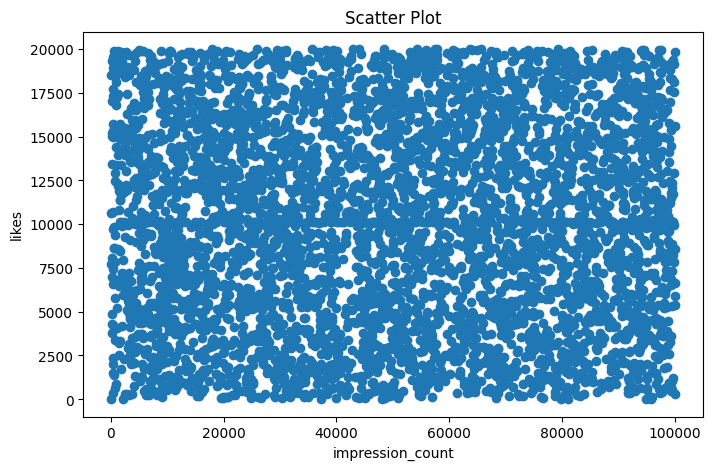

In [90]:
plt.figure(figsize=(8,5))
plt.scatter(df['impression_count'],df['likes'])
plt.xlabel('impression_count')
plt.ylabel('likes')
plt.title('Scatter Plot')
plt.show()

line : daily engagement trend

observes how average engagement changes over time

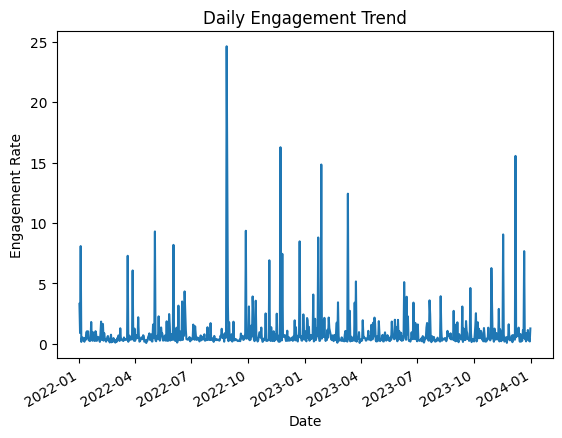

In [98]:
daily=df.groupby('posted_at')['engagement_rate'].mean()
daily.plot(kind='line')
plt.xlabel('Date')
plt.ylabel('Engagement Rate')
plt.title('Daily Engagement Trend')
plt.show()

bar: posts by category

compare the number of post in each category

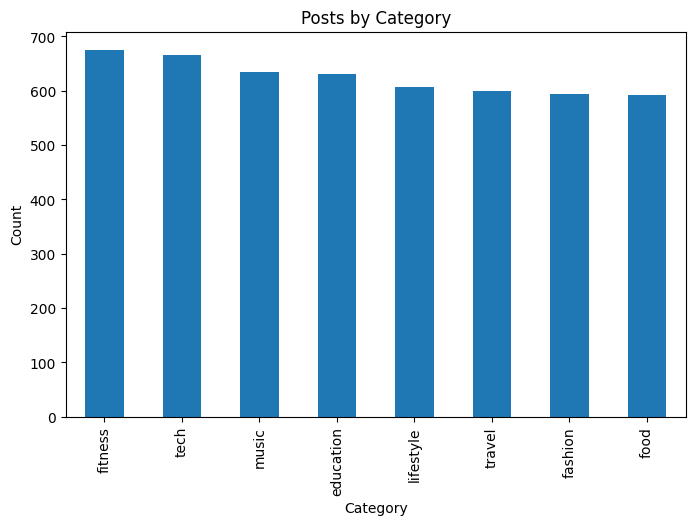

In [94]:
plt.figure(figsize=(8,5))
df['post_category'].value_counts().plot(kind='bar')
plt.xlabel('Category')
plt.ylabel('Count')
plt.title('Posts by Category')
plt.show()

pie : gender distribution

show the percentage distribution of gender categories

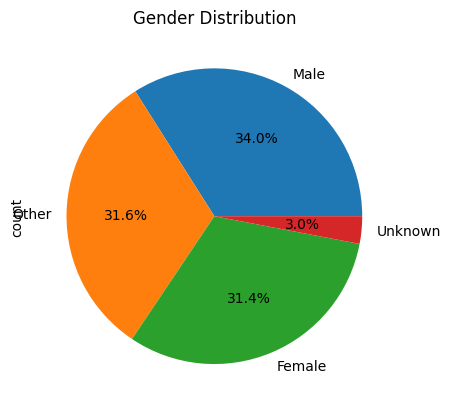

In [95]:
df['gender'].value_counts().plot(kind='pie',autopct='%1.1f%%')
plt.title('Gender Distribution')
plt.show()

histogram: age

to understand the distribution of ages

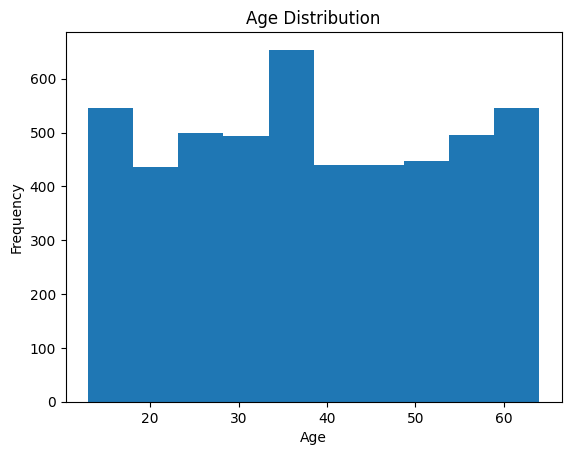

In [96]:
plt.hist(df['age'],bins=10)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

box : engagement rate

identify the median, spread and potential outliers in engagement rate

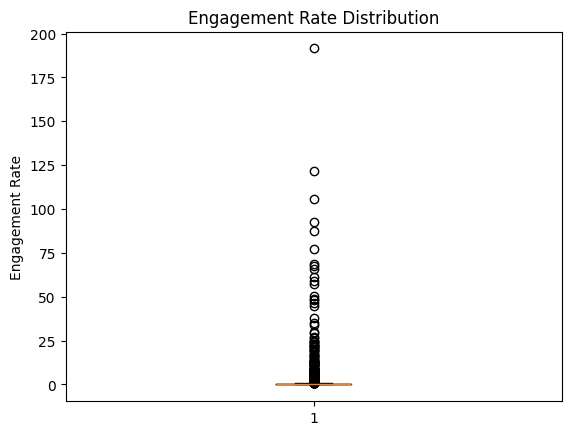

In [97]:
plt.boxplot(df['engagement_rate'])
plt.ylabel('Engagement Rate')
plt.title('Engagement Rate Distribution')
plt.show()

seaborn

count plot : post type

count post in each post type

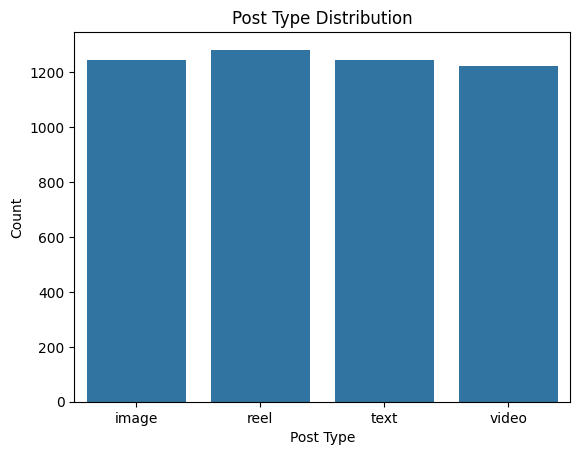

In [99]:
sns.countplot(data=df,x='post_type')
plt.xlabel('Post Type')
plt.ylabel('Count')
plt.title('Post Type Distribution')
plt.show()

bar plot : avg likes by category

compares average likes between categories

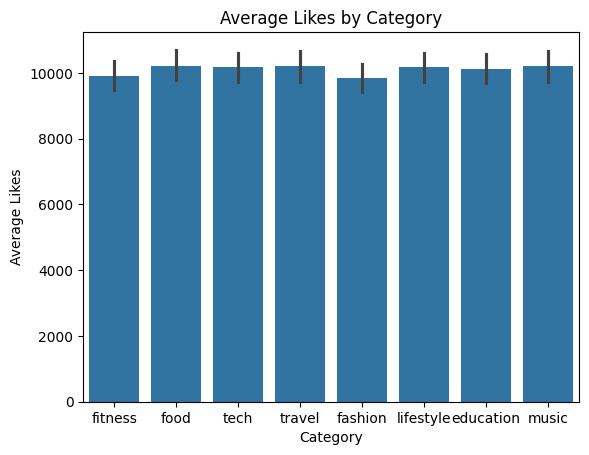

In [100]:
sns.barplot(data=df,x='post_category',y='likes')
plt.xlabel('Category')
plt.ylabel('Average Likes')
plt.title('Average Likes by Category')
plt.show()

violin : followers vs sentiment

compare the distribution of followers across sentiment categories

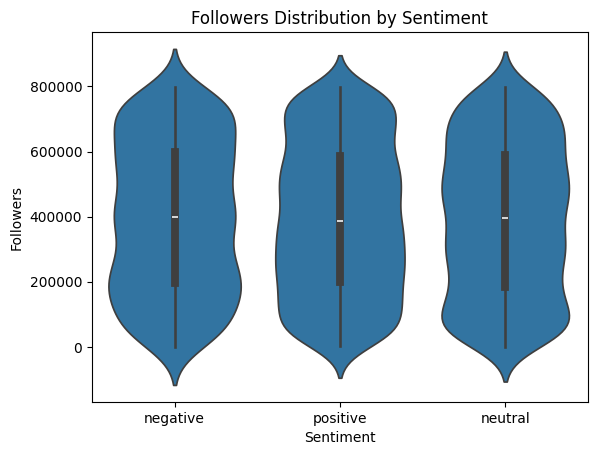

In [101]:
sns.violinplot(data=df,x='sentiment',y='follower_count')
plt.xlabel('Sentiment')
plt.ylabel('Followers')
plt.title('Followers Distribution by Sentiment')
plt.show()

pair plot: numeric features

examine pairwise relationship amoung the numerical variables

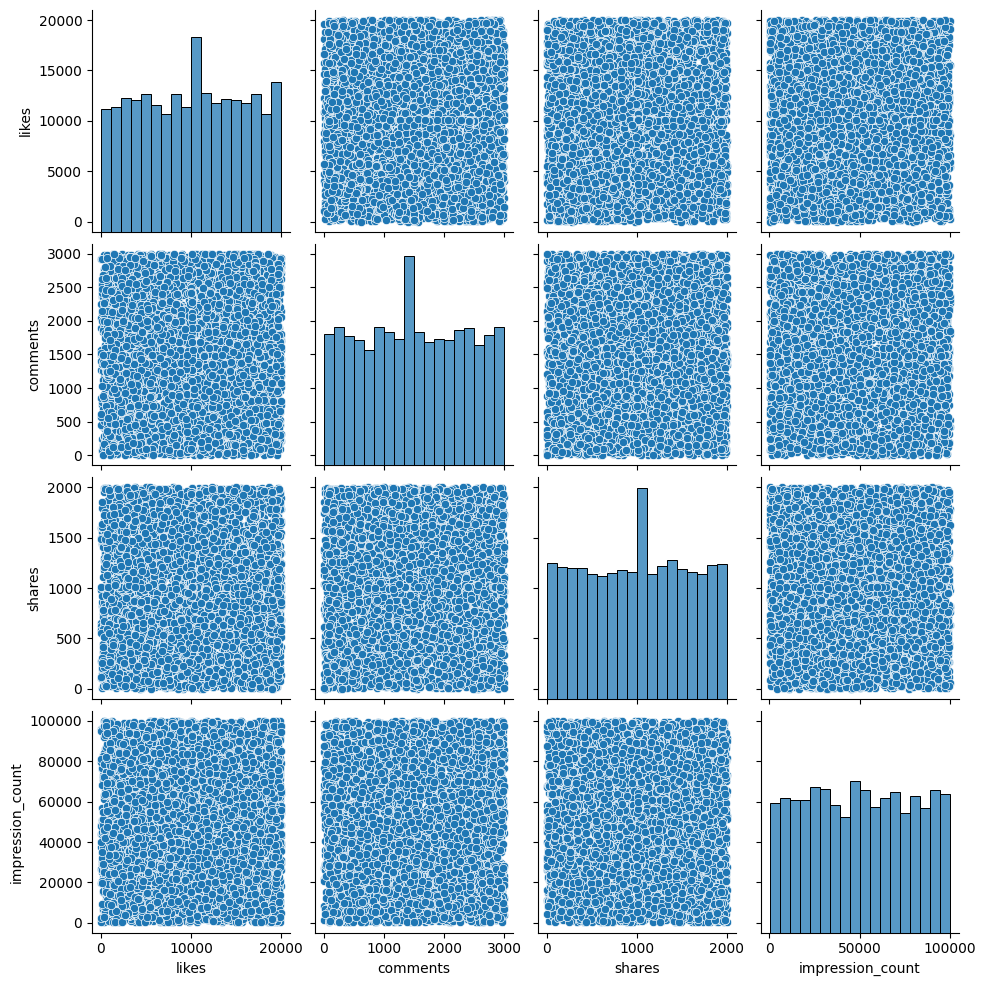

In [103]:
sns.pairplot(df[['likes','comments','shares','impression_count']])
plt.show()

heat map : correlation matrix

viaualize correlation between numerical variables

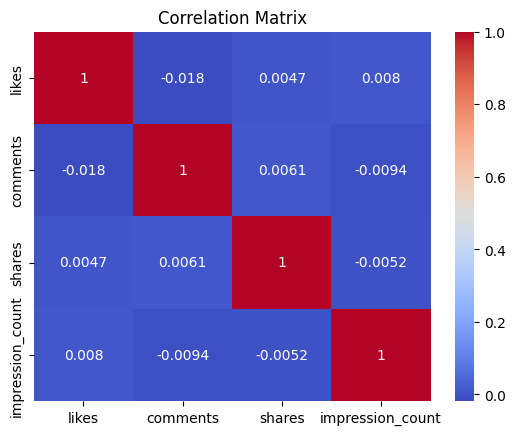

In [104]:
sns.heatmap(df[['likes','comments','shares','impression_count']].corr(),annot=True,cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

plotly

interactive linechart/bar chart/bubble/scatter chart

In [108]:
import plotly.express as px


In [112]:
fig=px.bar(df,x='post_type',y='likes',title='Average Likes by Post Type')
fig.show()

FINAL INSIGHTS

which post types have highest engagement

post type video has the highest engagement score

In [113]:
df.groupby('post_type')['engagement_score'].mean().sort_values(ascending=False)

,engagement_score
post_type,
video,12664.594286
image,12649.390537
text,12613.243775
reel,12524.031567


which countries have highest avg engagement rate

Brazil have the highest avg engagement rate

In [132]:
df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

,engagement_rate
country,
Brazil,1.540704
Australia,1.324339
France,1.146402
UAE,1.112352
Canada,0.916659
UK,0.850966
Japan,0.769623
Germany,0.759000
India,0.655005


In [116]:
df.groupby('sentiment')['engagement_score'].mean().sort_values(ascending=False)

,engagement_score
sentiment,
negative,12731.498958
positive,12665.799443
neutral,12448.163720


how age affects engagement
different age cateogies have diffferent engagement score it doesnt have a usual pattern engagement rate is high on age group of 24

In [134]:
df.groupby('age')['engagement_rate'].mean().sort_values(ascending=False)

,engagement_rate
age,
24.0,2.897327
55.0,2.599106
51.0,2.397295
48.0,1.675878
50.0,1.552627
41.0,1.540070
35.0,1.521596
47.0,1.402015
42.0,1.350772


performance difference for verified accounts

verified accounts have more engagement rate compared to non verified

In [135]:
df.groupby('is_verified')['engagement_rate'].mean()

,engagement_rate
is_verified,
False,0.954744
True,1.054250


best time of day for impressions

In [121]:
df.groupby('posted_at')['impression_count'].mean().sort_values(ascending=False)

,impression_count
posted_at,
2023-12-02,98263.5
2023-08-10,90304.5
2023-09-06,89909.0
2023-02-22,84897.0
2023-12-16,81594.0
...,...
2023-10-07,15330.0
2022-08-01,12526.0
2022-12-20,11483.0


device type impact on watch time

mainly mobile users have more watchtime compared to tablet and desktop

In [123]:
df.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

,watch_time_sec
device_type,
mobile,4087.830760
tablet,3979.736429
desktop,3974.792521


which sentiment perform best

mainly negative sentiment have more likes shares and comments

In [136]:
df.groupby('sentiment')[['likes','comments','shares']].mean()

,likes,comments,shares
sentiment,,,
negative,10208.096875,1516.094792,1007.307292
neutral,9923.194499,1528.404060,996.565160
positive,10180.062077,1480.650617,1005.086749


SOCIAL MEDIA ENGAGEMENT ANALYSIS SUMMARY OF FINDINGS

Objective: the objective of this project was to clean, analyze and visualize social media engagement data using python libraries including pandas, numpy, matplotlib, seaborn and plotly

Data cleaning : missing values were examined and handled using appropriate methods. duplicate records were identified in this data set there is no duplicates . data types and category labels were standardized. additional engagement metrics were created.

Content Performance: the analysis compared likes,comments, shares, engagement score and impressions across post type and categories. the highest performing post type is videos.

User trends: age groups and verified accounts status were compared to identify difference in engagement. the result showed mainly people of age 24 has the highest engagement score and verified users have highest engagement score.

Sentiment analysis: positive,negative and neutral posts were compared using engagement metrics. the sentiment category with highest engagement was negative.

CONCLUSION

The project demonstrated how data cleaning,exploratory analysis, statistical summaries and visualizations can reveal patterns in social media performance. the findings can help guide further investigation into content strategy and audience engagement.